<a href="https://colab.research.google.com/github/michelDol/simulacion/blob/main/Fundamentos_de_Simulaci%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



#  **Unidad de Aprendizaje:** Fundamentos de Simulación y Modelación Probabilística
* **Alumna:** Ing. Michel Margarita Dolores Avalos

---



# **Actividad 1** Comparación de modelos determinísticos y estocásticos
* **Objetivo:** El estudiante desarrollará un ejemplo computacional sencillo que permita comparar el comportamiento de un modelo determinístico y un modelo estocástico.



### Modelos de Crecimiento Poblacional: Determinista vs. Estocástico

Definiremos los mismos parámetros iniciales para ambos modelos:
* Población inicial ($N_0$): 100
* Tasa de crecimiento promedio ($r$): 0.05 (5%)
* Tiempo de simulación ($T$): 50 pasos
* Desviación estándar del componente aleatorio ($

sigma$): 0.08

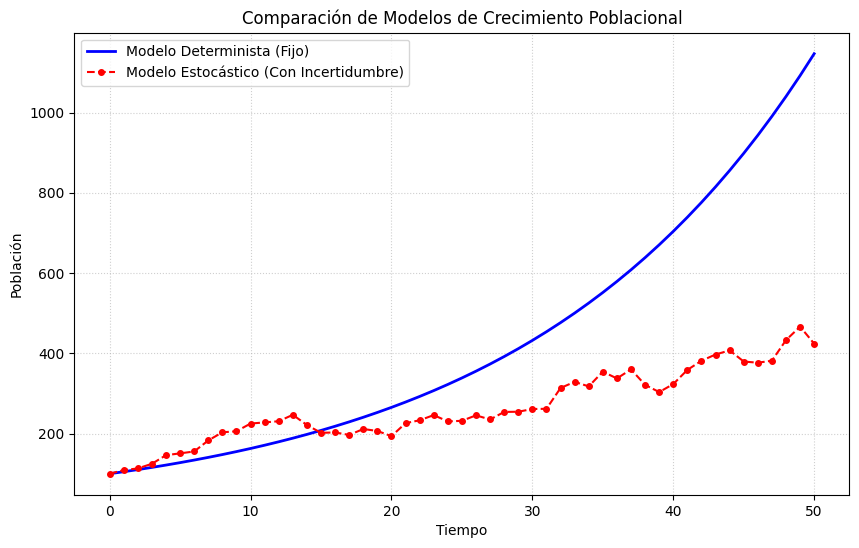

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Fijar semilla para reproducibilidad del modelo estocástico
np.random.seed(42)

# Parámetros
N0 = 100
r = 0.05
T = 50
sigma = 0.08

tiempo = np.arange(0, T + 1)

# 1. Modelo Determinista: N_t = N_0 * (1 + r)^t
pob_determinista = N0 * ((1 + r) ** tiempo)

# 2. Modelo Estocástico: N_t = N_{t-1} * (1 + r + e_t) donde e_t ~ N(0, sigma^2)
pob_estocastica = np.zeros(T + 1)
pob_estocastica[0] = N0
for t in range(1, T + 1):
    ruido = np.random.normal(0, sigma)
    pob_estocastica[t] = pob_estocastica[t-1] * (1 + r + ruido)
    # Evitar poblaciones negativas
    if pob_estocastica[t] < 0:
        pob_estocastica[t] = 0

# Crear DataFrame para visualización
df_resultados = pd.DataFrame({
    'Tiempo': tiempo,
    'Determinista': pob_determinista,
    'Estocastico': pob_estocastica
})

# Graficar resultados
plt.figure(figsize=(10, 6))
plt.plot(df_resultados['Tiempo'], df_resultados['Determinista'], label='Modelo Determinista (Fijo)', color='blue', linewidth=2)
plt.plot(df_resultados['Tiempo'], df_resultados['Estocastico'], label='Modelo Estocástico (Con Incertidumbre)', color='red', linestyle='--', marker='o', markersize=4)
plt.title('Comparación de Modelos de Crecimiento Poblacional')
plt.xlabel('Tiempo')
plt.ylabel('Población')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

### Interpretación de los Resultados

El modelo determinista muestra una trayectoria suave y predecible, donde la población crece exponencialmente de manera constante. En cambio, el modelo estocástico introduce fluctuaciones debido a la variabilidad ambiental aleatoria simulada paso a paso. Aunque ambos comparten los mismos parámetros iniciales, el resultado estocástico diverge y presenta ascensos y descensos imprevistos, reflejando un escenario mucho más realista.

Incorporar la incertidumbre en las simulaciones es fundamental porque los sistemas reales nunca son perfectamente constantes. Permite evaluar riesgos, predecir escenarios extremos (como la extinción o sobrepoblación) y diseñar estrategias de planificación robustas ante eventos imprevistos. Un análisis puramente determinista ignora la posibilidad de desviaciones críticas, ofreciendo una falsa sensación de certeza.

# **Actividad 2** Generación de números y variables aleatorias
* **Objetivo:** El estudiante implementará procedimientos básicos de generación de números pseudoaleatorios y variables aleatorias, con el propósito de analizar sus propiedades estadísticas y su comportamiento gráfico.

### Etapas de la Simulación:
1. Generación de 1,000 números pseudoaleatorios con distribución Uniforme $U(0,1)$.
2. Generación de 1,000 observaciones para las distribuciones: Normal $N(0,1)$, Exponencial $\text{Exp}(\lambda=1)$ y Poisson $\text{Poisson}(\lambda=5)$.
3. Visualización gráfica mediante histogramas.
4. Análisis comparativo de estadísticas descriptivas (empíricas vs. teóricas).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Establecer semilla para reproducibilidad
np.random.seed(42)
n_muestras = 1000

# Generación de variables aleatorias
uniforme = np.random.uniform(0, 1, n_muestras)
normal = np.random.normal(0, 1, n_muestras)
exponencial = np.random.exponential(scale=1.0, size=n_muestras) # lambda = 1 -> escala (1/lambda) = 1.0
poisson = np.random.poisson(lam=5, size=n_muestras)

# Diccionario de datos
datos = {
    'Uniforme U(0,1)': uniforme,
    'Normal N(0,1)': normal,
    'Exponencial Exp(1)': exponencial,
    'Poisson Poisson(5)': poisson
}

# Calcular estadísticas descriptivas
resumen_stats = []
for nombre, muestra in datos.items():
    resumen_stats.append({
        'Distribución': nombre,
        'Media Empírica': np.mean(muestra),
        'Varianza Empírica': np.var(muestra, ddof=1),
        'Desv. Estándar Empírica': np.std(muestra, ddof=1),
        'Mínimo': np.min(muestra),
        'Máximo': np.max(muestra)
    })

df_stats = pd.DataFrame(resumen_stats)

# Agregar valores teóricos para comparación
teoricos = {
    'Uniforme U(0,1)': {'Media Teórica': 0.5, 'Varianza Teórica': 1/12},
    'Normal N(0,1)': {'Media Teórica': 0.0, 'Varianza Teórica': 1.0},
    'Exponencial Exp(1)': {'Media Teórica': 1.0, 'Varianza Teórica': 1.0},
    'Poisson Poisson(5)': {'Media Teórica': 5.0, 'Varianza Teórica': 5.0}
}

df_stats['Media Teórica'] = df_stats['Distribución'].map(lambda x: teoricos[x]['Media Teórica'])
df_stats['Varianza Teórica'] = df_stats['Distribución'].map(lambda x: teoricos[x]['Varianza Teórica'])

# Reordenar columnas para mejor lectura
columnas_ordenadas = [
    'Distribución', 'Media Empírica', 'Media Teórica',
    'Varianza Empírica', 'Varianza Teórica',
    'Desv. Estándar Empírica', 'Mínimo', 'Máximo'
]
display(df_stats[columnas_ordenadas])

,Distribución,Media Empírica,Media Teórica,Varianza Empírica,Varianza Teórica,Desv. Estándar Empírica,Mínimo,Máximo
0,"Uniforme U(0,1)",0.490257,0.5,0.085344,0.083333,0.292137,0.004632,0.999718
1,"Normal N(0,1)",0.098896,0.0,0.977989,1.000000,0.988933,-2.921350,3.193108
2,Exponencial Exp(1),0.968714,1.0,0.891887,1.000000,0.944398,0.000012,6.128823
3,Poisson Poisson(5),4.936000,5.0,4.278182,5.000000,2.068377,0.000000,14.000000


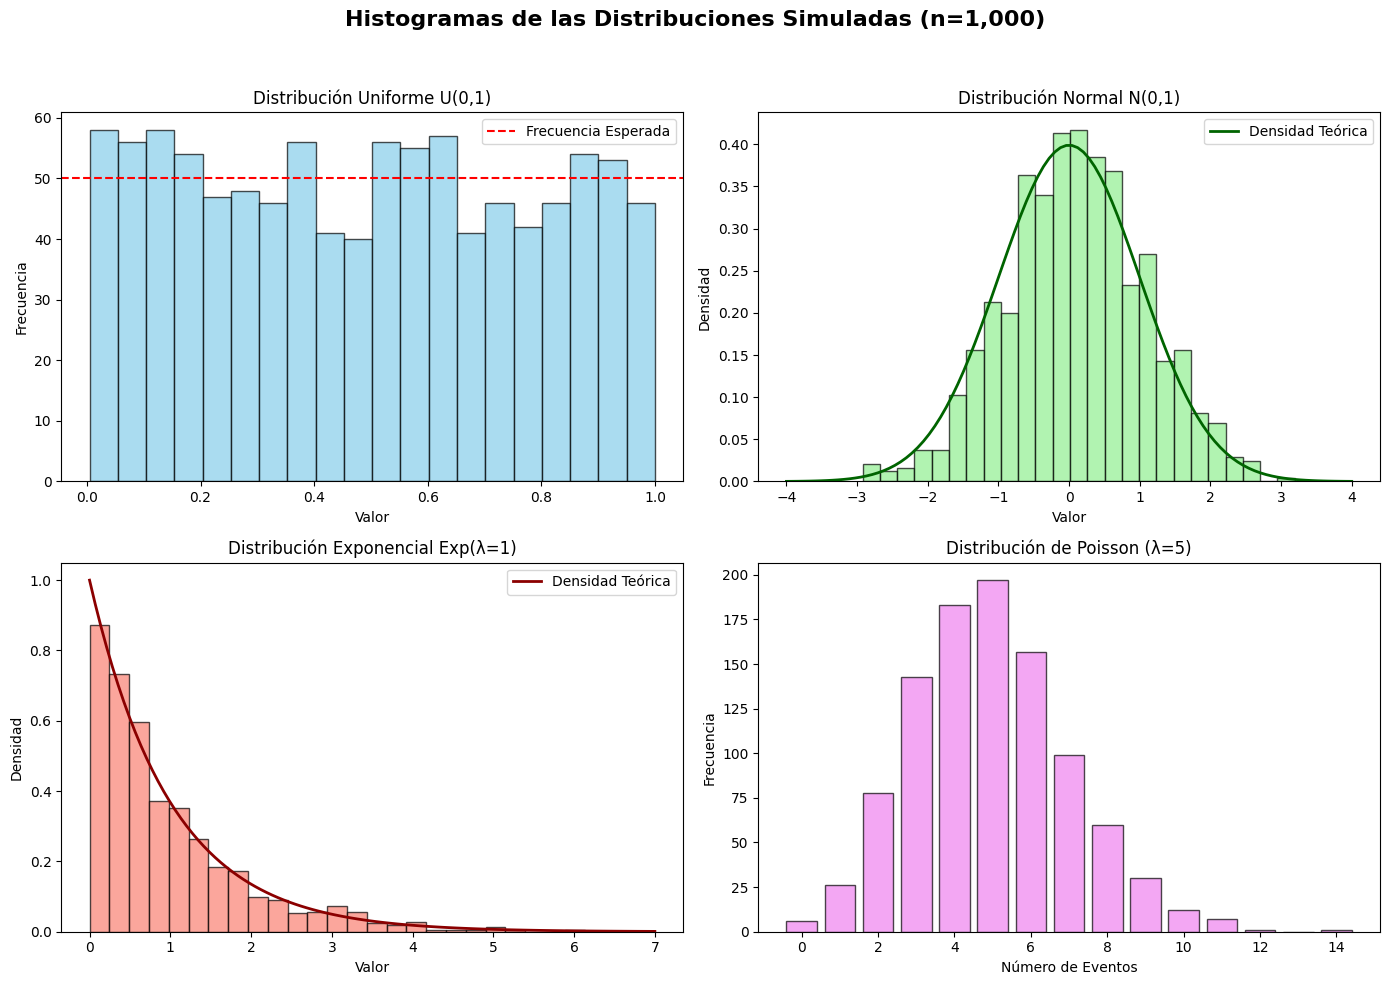

In [3]:
# Configurar los gráficos de distribución
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Histogramas de las Distribuciones Simuladas (n=1,000)', fontsize=16, fontweight='bold')

# Uniforme
axes[0, 0].hist(uniforme, bins=20, color='skyblue', edgecolor='black', alpha=0.7)
axes[0, 0].axhline(y=1000/20, color='red', linestyle='--', label='Frecuencia Esperada')
axes[0, 0].set_title('Distribución Uniforme U(0,1)')
axes[0, 0].set_xlabel('Valor')
axes[0, 0].set_ylabel('Frecuencia')
axes[0, 0].legend()

# Normal
axes[0, 1].hist(normal, bins=25, color='lightgreen', edgecolor='black', alpha=0.7, density=True)
x_norm = np.linspace(-4, 4, 100)
p_norm = (1 / np.sqrt(2 * np.pi)) * np.exp(-x_norm**2 / 2)
axes[0, 1].plot(x_norm, p_norm, color='darkgreen', linewidth=2, label='Densidad Teórica')
axes[0, 1].set_title('Distribución Normal N(0,1)')
axes[0, 1].set_xlabel('Valor')
axes[0, 1].set_ylabel('Densidad')
axes[0, 1].legend()

# Exponencial
axes[1, 0].hist(exponencial, bins=25, color='salmon', edgecolor='black', alpha=0.7, density=True)
x_exp = np.linspace(0, 7, 100)
p_exp = np.exp(-x_exp)
axes[1, 0].plot(x_exp, p_exp, color='darkred', linewidth=2, label='Densidad Teórica')
axes[1, 0].set_title('Distribución Exponencial Exp(λ=1)')
axes[1, 0].set_xlabel('Valor')
axes[1, 0].set_ylabel('Densidad')
axes[1, 0].legend()

# Poisson
# Al ser discreta, usamos barras alineadas a los enteros
bins_poisson = np.arange(0, np.max(poisson) + 2) - 0.5
axes[1, 1].hist(poisson, bins=bins_poisson, color='violet', edgecolor='black', alpha=0.7, rwidth=0.8)
axes[1, 1].set_title('Distribución de Poisson (λ=5)')
axes[1, 1].set_xlabel('Número de Eventos')
axes[1, 1].set_ylabel('Frecuencia')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### Análisis Comparativo e Interpretación

Las simulaciones demuestran una alta correspondencia entre las estadísticas empíricas y los parámetros teóricos debido al tamaño muestral ($n=1,000$). La distribución Uniforme muestra valores equitativamente distribuidos con una media muy cercana a $0.5$. La Normal se agrupa simétricamente alrededor de $0$, con su característica forma de campana y una varianza próxima a $1.0$. Por su parte, la Exponencial presenta una asimetría positiva pronunciada, donde la mayoría de los valores se concentran cerca de cero, cumpliendo con la propiedad teórica de que su media y varianza son equivalentes (~$1.0$). Finalmente, la distribución discreta de Poisson exhibe un comportamiento unimodal centrado en su tasa teórica $\lambda = 5$.

Esta congruencia valida el generador de números pseudoaleatorios bajo la semilla establecida, confirmando que la simulación por computadora recrea con precisión el comportamiento probabilístico teórico esencial para modelar la incertidumbre real.

## Conclusión General

El desarrollo de ambas actividades permite comprender el valor fundamental de la simulación computacional y la probabilidad en la representación de fenómenos reales. Mientras que la **Actividad 1** demostró cómo los enfoques estocásticos capturan la variabilidad natural y el riesgo que los modelos deterministas estáticos ignoran, la **Actividad 2** validó la precisión con la que los métodos numéricos y generadores de números pseudoaleatorios reproducen el comportamiento teórico de las distribuciones de probabilidad bajo condiciones controladas.

En conjunto, estas prácticas evidencian que el análisis probabilístico y la modelación matemática no solo enriquecen la comprensión de sistemas complejos, sino que proporcionan herramientas robustas para la toma de decisiones informada, permitiendo anticipar escenarios diversos bajo un marco formal de gestión de la incertidumbre.